In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/aravindas01/ipl-2022dataset/Book_ipl22_ver_33.csv
/kaggle/input/datasets/nevildhinoja/e-commerce-sales-prediction-dataset/Ecommerce_Sales_Prediction_Dataset.csv
/kaggle/input/datasets/wingsgrace/my-datasets/insurance.csv
/kaggle/input/datasets/wingsgrace/my-datasets/heart.csv


In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [4]:
df = pd.read_csv("/kaggle/input/datasets/wingsgrace/my-datasets/insurance.csv")

In [5]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


EDA

In [6]:
df.shape

(1338, 7)

In [7]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [9]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

In [10]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

# checking numerical and categorical columns

In [11]:
df.select_dtypes(include = 'number').columns

Index(['age', 'bmi', 'children', 'charges'], dtype='object')

In [12]:
df.select_dtypes(include = 'object').columns

Index(['sex', 'smoker', 'region'], dtype='object')

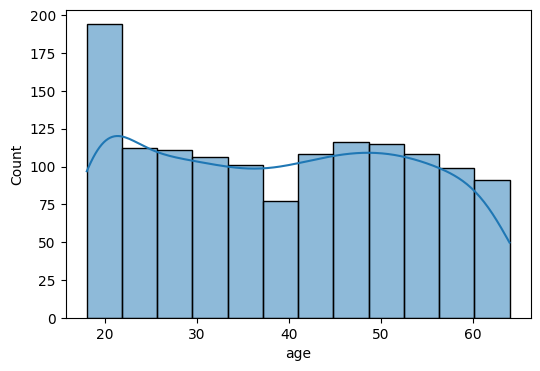

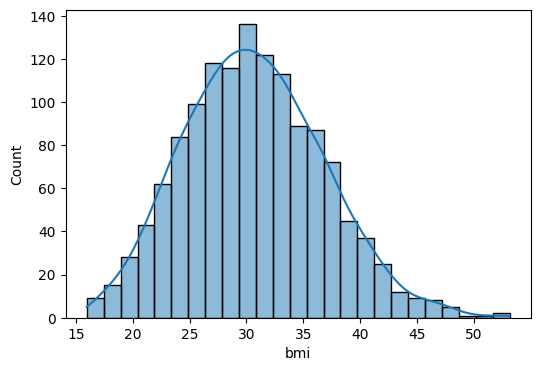

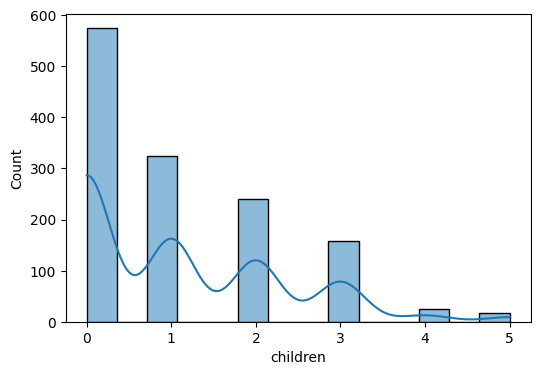

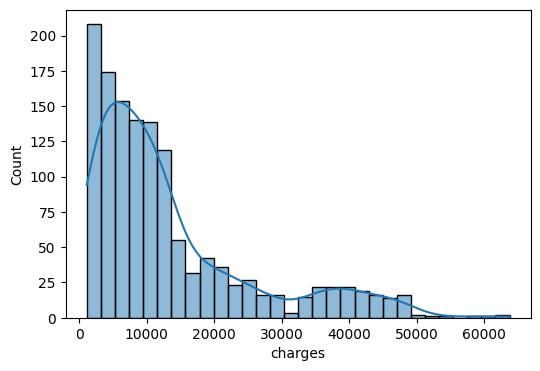

In [13]:
numerical_columns = ['age','bmi','children','charges']
for i in numerical_columns :
    plt.figure(figsize = (6,4))
    sns.histplot(df[i],kde = True)

<Axes: xlabel='sex', ylabel='count'>

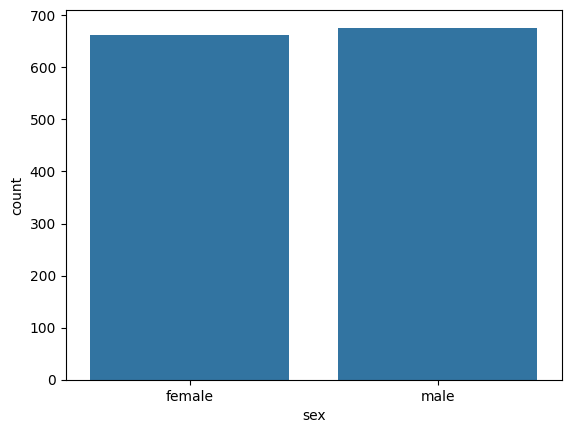

In [14]:

sns.countplot(x = df["sex"])


<Axes: xlabel='smoker', ylabel='count'>

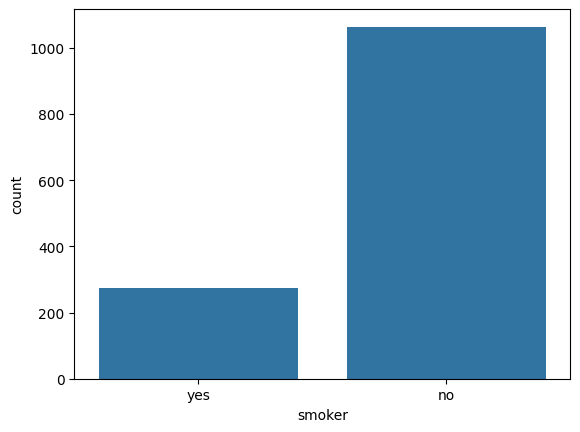

In [15]:
sns.countplot(x = df['smoker'])

<Axes: xlabel='region', ylabel='count'>

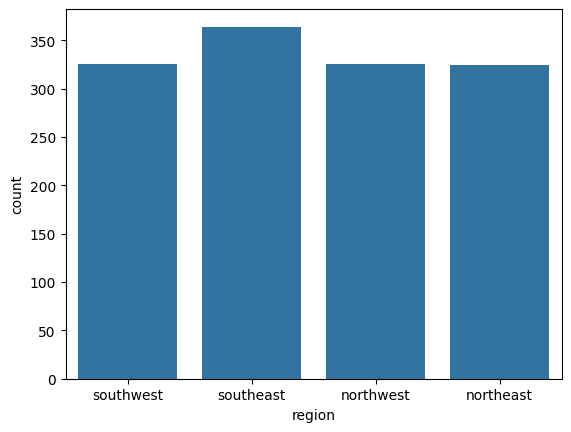

In [16]:
sns.countplot(x = df['region'])

<Axes: xlabel='children', ylabel='count'>

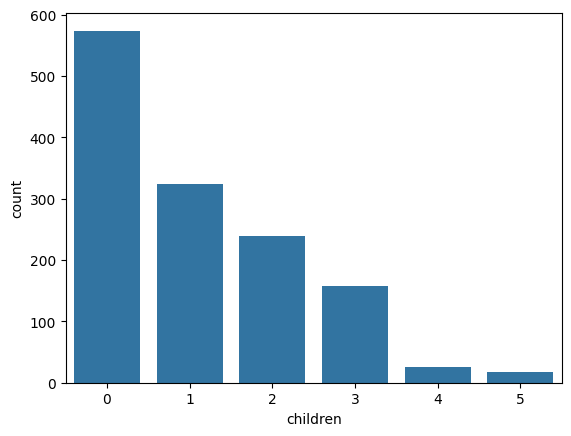

In [17]:
sns.countplot(x = df['children'])

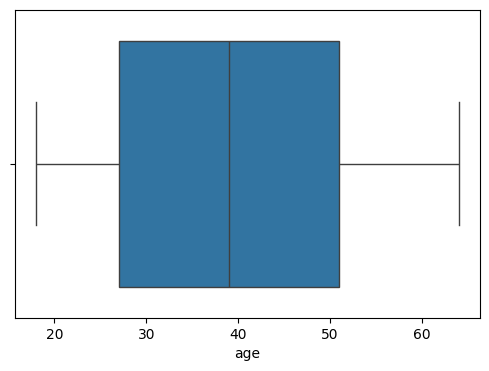

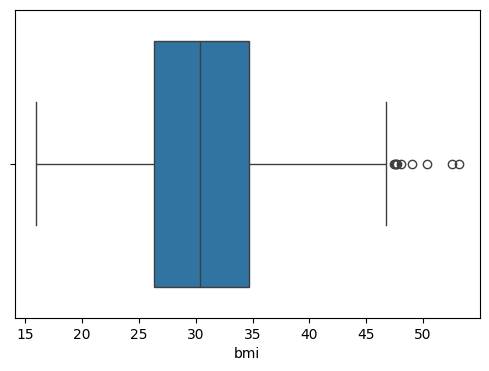

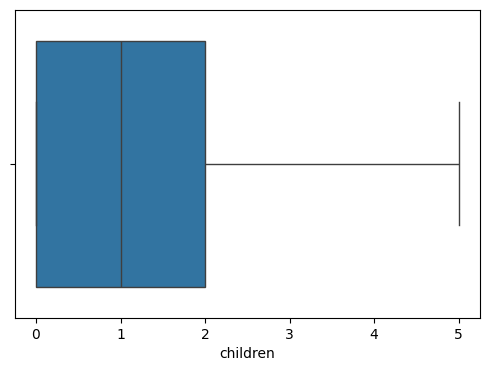

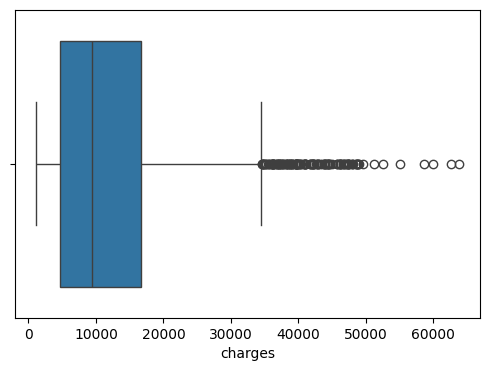

In [18]:
for col in numerical_columns :
    plt.figure(figsize = (6,4))
    sns.boxplot(x = df[col])

<Axes: >

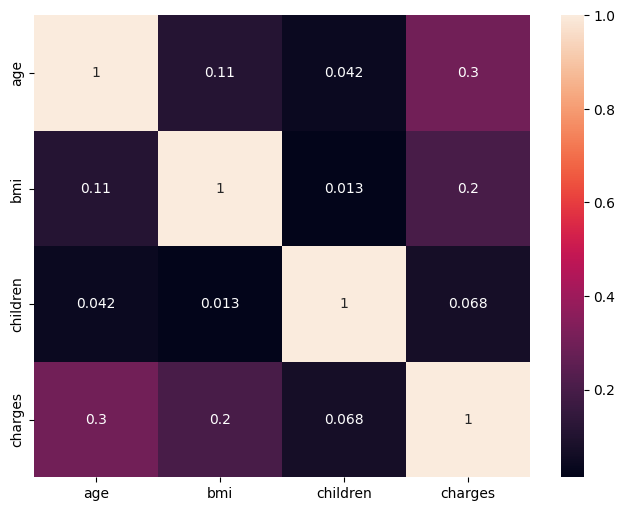

In [19]:
plt.figure(figsize = (8,6))
sns.heatmap(df.corr(numeric_only = True),annot = True)

data cleaning and preprocessing 

In [20]:
df_cleaned = df.copy()
df_cleaned

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [21]:
df.shape

(1338, 7)

In [22]:
df.drop_duplicates(inplace = True)
df_cleaned.shape

(1338, 7)

In [23]:
df_cleaned.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

changing categorical value to numeric

In [24]:
df_cleaned['sex'].value_counts()

sex
male      676
female    662
Name: count, dtype: int64

In [25]:
df_cleaned['sex'] = df_cleaned['sex'].map({"male":0,"female": 1})


In [26]:
df_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,yes,southwest,16884.92400
1,18,0,33.770,1,no,southeast,1725.55230
2,28,0,33.000,3,no,southeast,4449.46200
3,33,0,22.705,0,no,northwest,21984.47061
4,32,0,28.880,0,no,northwest,3866.85520


In [27]:
df_cleaned['smoker'] = df_cleaned['smoker'].map({"no": 0,"yes":1})
df_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520


splitting region column into 4 new columns

In [28]:
df['region'].value_counts()

region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64

In [29]:
df_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520


In [30]:
df_cleaned.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

In [31]:
df_cleaned['region_northeast'] = (
    df['region'] == 'northeast'
)

In [32]:
df_cleaned.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges',
       'region_northeast'],
      dtype='object')

In [33]:
df_cleaned.head()

,age,sex,bmi,children,smoker,region,charges,region_northeast
0,19,1,27.900,0,1,southwest,16884.92400,False
1,18,0,33.770,1,0,southeast,1725.55230,False
2,28,0,33.000,3,0,southeast,4449.46200,False
3,33,0,22.705,0,0,northwest,21984.47061,False
4,32,0,28.880,0,0,northwest,3866.85520,False


In [34]:
df_cleaned.isnull().sum()

age                 0
sex                 0
bmi                 0
children            0
smoker              0
region              0
charges             0
region_northeast    1
dtype: int64

In [35]:
df_cleaned['region_northeast'] = (
    df_cleaned['region_northeast'].fillna(0)
)

In [36]:
df_cleaned.rename(columns = {
    "sex" : "is_female",
    "smoker" : "is_smoker"
},inplace = True)

In [37]:
df_cleaned

,age,is_female,bmi,children,is_smoker,region,charges,region_northeast
0,19,1,27.900,0,1,southwest,16884.92400,False
1,18,0,33.770,1,0,southeast,1725.55230,False
2,28,0,33.000,3,0,southeast,4449.46200,False
3,33,0,22.705,0,0,northwest,21984.47061,False
4,32,0,28.880,0,0,northwest,3866.85520,False
...,...,...,...,...,...,...,...,...
1333,50,0,30.970,3,0,northwest,10600.54830,False
1334,18,1,31.920,0,0,northeast,2205.98080,True
1335,18,1,36.850,0,0,southeast,1629.83350,False
1336,21,1,25.800,0,0,southwest,2007.94500,False


extraction and feature engineering 

<Axes: xlabel='bmi', ylabel='Count'>

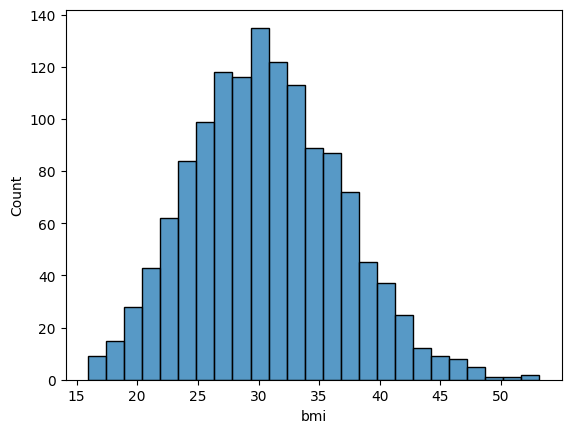

In [38]:
sns.histplot(df["bmi"])

In [39]:
bins = [0,18.5,25,30,float('inf')]
labels = ["underweight","Healthy","overweight","obese"]
df_cleaned["bmi_category"] = pd.cut(df_cleaned["bmi"]
                                   ,bins = bins
                                   , labels = labels
                                   ,right = False)

In [40]:
df_cleaned

,age,is_female,bmi,children,is_smoker,region,charges,region_northeast,bmi_category
0,19,1,27.900,0,1,southwest,16884.92400,False,overweight
1,18,0,33.770,1,0,southeast,1725.55230,False,obese
2,28,0,33.000,3,0,southeast,4449.46200,False,obese
3,33,0,22.705,0,0,northwest,21984.47061,False,Healthy
4,32,0,28.880,0,0,northwest,3866.85520,False,overweight
...,...,...,...,...,...,...,...,...,...
1333,50,0,30.970,3,0,northwest,10600.54830,False,obese
1334,18,1,31.920,0,0,northeast,2205.98080,True,obese
1335,18,1,36.850,0,0,southeast,1629.83350,False,obese
1336,21,1,25.800,0,0,southwest,2007.94500,False,overweight


In [41]:
df_cleaned.columns

Index(['age', 'is_female', 'bmi', 'children', 'is_smoker', 'region', 'charges',
       'region_northeast', 'bmi_category'],
      dtype='object')

In [42]:
# one hot encoding

In [43]:
df_cleaned = pd.get_dummies(df_cleaned,columns = ["bmi_category"])
df_cleaned

,age,is_female,bmi,children,is_smoker,region,charges,region_northeast,bmi_category_underweight,bmi_category_Healthy,bmi_category_overweight,bmi_category_obese
0,19,1,27.900,0,1,southwest,16884.92400,False,False,False,True,False
1,18,0,33.770,1,0,southeast,1725.55230,False,False,False,False,True
2,28,0,33.000,3,0,southeast,4449.46200,False,False,False,False,True
3,33,0,22.705,0,0,northwest,21984.47061,False,False,True,False,False
4,32,0,28.880,0,0,northwest,3866.85520,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30.970,3,0,northwest,10600.54830,False,False,False,False,True
1334,18,1,31.920,0,0,northeast,2205.98080,True,False,False,False,True
1335,18,1,36.850,0,0,southeast,1629.83350,False,False,False,False,True
1336,21,1,25.800,0,0,southwest,2007.94500,False,False,False,True,False


In [44]:
df_cleaned.drop('region',axis = 1,inplace = True)

In [63]:
df_cleaned = df_cleaned.astype(int)

In [46]:
df_cleaned.columns

Index(['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges',
       'region_northeast', 'bmi_category_underweight', 'bmi_category_Healthy',
       'bmi_category_overweight', 'bmi_category_obese'],
      dtype='object')

In [47]:
df.corr(numeric_only=True, method='pearson')['charges']

age         0.298308
bmi         0.198401
children    0.067389
charges     1.000000
Name: charges, dtype: float64

In [64]:
final_df = df_cleaned
final_df

,age,is_female,bmi,children,is_smoker,charges,region_northeast,bmi_category_underweight,bmi_category_Healthy,bmi_category_overweight,bmi_category_obese
0,19,1,27,0,1,16884,0,0,0,1,0
1,18,0,33,1,0,1725,0,0,0,0,1
2,28,0,33,3,0,4449,0,0,0,0,1
3,33,0,22,0,0,21984,0,0,1,0,0
4,32,0,28,0,0,3866,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30,3,0,10600,0,0,0,0,1
1334,18,1,31,0,0,2205,1,0,0,0,1
1335,18,1,36,0,0,1629,0,0,0,0,1
1336,21,1,25,0,0,2007,0,0,0,1,0


In [79]:
# linear regression 

In [65]:
from sklearn.model_selection import train_test_split
x = final_df.drop('charges',axis = 1)
y = final_df['charges']
x_train, x_test, y_train, y_test = train_test_split(
    x,y, test_size=0.2, random_state=42
)
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(x_train,y_train)

LinearRegression()

In [66]:
y_pred = model.predict(x_test)

In [67]:
y_test

764      9095
887      5272
890     29330
1293     9301
259     33750
        ...  
109     47055
575     12222
535      6067
543     63770
846      9872
Name: charges, Length: 268, dtype: int64

In [68]:
y_pred

array([ 8.66278613e+03,  8.72925697e+03,  3.58191615e+04,  8.71659049e+03,
        2.81023441e+04,  9.60564680e+03, -5.73864390e+00,  1.64553370e+04,
       -4.15581389e+01,  9.73039041e+03,  2.78768192e+04,  1.08341117e+04,
        3.86775902e+03,  3.71753472e+04,  3.93351639e+04,  3.66835145e+04,
        1.38804563e+04,  3.61146752e+04,  8.13749946e+03,  3.04435422e+04,
        3.69707608e+03,  1.15099783e+04,  4.36249261e+03,  6.49018752e+03,
        1.00014448e+04,  1.41079475e+04,  1.52825791e+04,  7.68544683e+03,
        9.25670131e+03,  4.10651073e+03,  7.94358637e+03,  1.41868278e+04,
        5.21733457e+03,  3.82423441e+03,  6.57437464e+03,  1.23626981e+04,
        1.57404973e+03,  7.45150527e+03,  3.26834751e+04,  3.32018506e+04,
        2.90602448e+03,  5.63239857e+03,  1.46786605e+04,  1.07843281e+04,
        9.19601382e+03,  1.13682399e+04,  5.97540096e+03,  2.95408219e+03,
        3.58337416e+04,  8.92990436e+03,  1.61324762e+04,  1.03688590e+03,
        1.10746591e+04,  

In [72]:
from sklearn.metrics import r2_score
r2 = r2_score(y_test,y_pred)
r2

0.7787047157610867

1. 

In [77]:
n = x_test.shape[0]
p = x_test.shape[1]
adjusted_r2 = 1 - ((1-r2)*(n-1))/(n-p-1)

adjusted_r2

0.7700940043121017

**second project**

In [48]:
df = pd.read_csv("/kaggle/input/datasets/wingsgrace/my-datasets/heart.csv")

In [49]:
df

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,M,TA,110,264,0,Normal,132,N,1.2,Flat,1
914,68,M,ASY,144,193,1,Normal,141,N,3.4,Flat,1
915,57,M,ASY,130,131,0,Normal,115,Y,1.2,Flat,1
916,57,F,ATA,130,236,0,LVH,174,N,0.0,Flat,1


**EDA**

In [50]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [51]:
df.shape

(918, 12)

In [52]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [53]:
df.isnull().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

In [54]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [55]:
df.select_dtypes(include = 'number').columns

Index(['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak',
       'HeartDisease'],
      dtype='object')

In [56]:
df.duplicated().sum()

np.int64(0)

<Axes: xlabel='HeartDisease'>

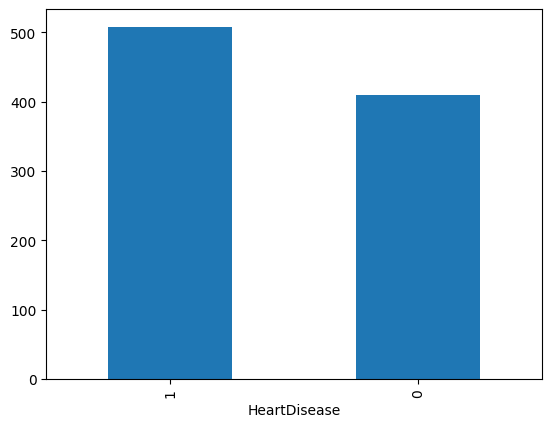

In [57]:
df['HeartDisease'].value_counts().plot(kind = "bar")